<a href="https://colab.research.google.com/github/Temuukl/uujee01/blob/main/Forklift_detection_yolov8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🏗️ Forklift Detection — Object Detection 실습

**ConstructionAI 2D 인식 기술 실습**: 데이터 준비 → 라벨 이해 → 학습 → 검증 → 추론(Test)

앞서 `cv_2d_recognition` 폴더에서 만든 Object Detection 패널은 **가짜로 그려 넣은 박스**였습니다.
이번에는 실제 데이터셋으로 **진짜 모델을 학습**시켜서, 진짜 안전모(Helmet) 탐지를 해봅니다.

사용할 데이터셋: **forklift** (`CV/dataset` 폴더에 이미 준비되어 있는 것, 원본은 Roboflow Universe)
- 이미지 수: 총 200장 (train 139 / valid 39 / test 22)
- 클래스: `Helmet` (안전모) — 단일 클래스 탐지


**진행 순서**
1. 환경 설정 (GPU 확인, 라이브러리 설치)
2. 데이터셋 다운로드 (Google Drive)
3. 데이터 · 라벨 형식 이해하기
4. YOLOv8 모델 학습 (Train)
5. 검증 (Validation)
6. 추론 (Inference / Test) — 우리 현장 사진으로도 직접 테스트!

> ⚠️ **시작 전에**: 상단 메뉴 `런타임(Runtime) → 런타임 유형 변경(Change runtime type) → 하드웨어 가속기: GPU (T4)` 로 설정하세요.

## 1. 환경 설정

In [1]:
# GPU가 정상적으로 잡혔는지 확인 (Tesla T4 등이 보여야 합니다)
!nvidia-smi

Fri Nov 13 04:10:23 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# 필요한 라이브러리 설치
!pip install -q ultralytics

import ultralytics
ultralytics.checks()

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


## 2. 데이터셋 다운로드 (Google Drive)

이번 실습은 이미 라벨링까지 끝난 데이터셋을 공유 Google Drive 링크에서 바로 받아옵니다.
Roboflow 계정이나 API 키가 필요 없습니다 — 아래 셀을 그대로 실행하면 됩니다.

> 💡 참고: 이 데이터셋의 원본은 Roboflow Universe의 [construction-helmet-nnque](https://universe.roboflow.com/ido/construction-helmet-nnque) 프로젝트입니다.
> 만약 이미지를 더 추가하거나 직접 라벨링해보고 싶다면, 저 링크에서 Roboflow 계정으로 프로젝트를 열어 이미지를 업로드하고 박스를 그려볼 수 있습니다.

In [3]:
!pip install -q gdown
import gdown
import zipfile
import os

# 공유 Google Drive 파일 ID
FILE_ID = "16mTK9TnEojC4G-dsz6UX4W3o2iGDWGoN"
DATA_ROOT = "dataset"

gdown.download(id=FILE_ID, output="dataset.zip", quiet=False)

with zipfile.ZipFile("dataset.zip", "r") as z:
    z.extractall(DATA_ROOT)

# Roboflow 기본 export의 data.yaml은 "../train/images"처럼 상위 폴더 기준 상대경로로 되어 있어서
# 이 폴더 구조(압축 해제 위치) 그대로는 경로가 깨집니다. 우리 구조에 맞게 고쳐줍니다.
yaml_path = f"{DATA_ROOT}/data.yaml"
with open(yaml_path) as f:
    content = f.read()
content = (content
           .replace("../train/images", "train/images")
           .replace("../valid/images", "valid/images")
           .replace("../test/images", "test/images"))
with open(yaml_path, "w") as f:
    f.write(content)

print("\n다운로드 및 압축 해제 완료! 폴더 구조:")
!find {DATA_ROOT} -maxdepth 2

Downloading...
From: https://drive.google.com/uc?id=16mTK9TnEojC4G-dsz6UX4W3o2iGDWGoN
To: /content/dataset.zip
100%|██████████| 15.1M/15.1M [00:00<00:00, 36.7MB/s]


다운로드 및 압축 해제 완료! 폴더 구조:
dataset
dataset/train
dataset/train/labels
dataset/train/images
dataset/test
dataset/test/labels
dataset/test/images
dataset/data.yaml
dataset/valid
dataset/valid/labels
dataset/valid/images
dataset/README.roboflow.txt


## 3. 데이터 · 라벨 형식 이해하기

In [4]:
import yaml

with open(f"{DATA_ROOT}/data.yaml") as f:
    data_yaml = yaml.safe_load(f)

print("클래스 목록:", data_yaml["names"])
print("클래스 수 (nc):", data_yaml["nc"])

클래스 목록: ['forklift']
클래스 수 (nc): 1


In [5]:
import os

# split(train/valid/test)별 이미지 수 확인
for split in ["train", "valid", "test"]:
    img_dir = f"{DATA_ROOT}/{split}/images"
    if os.path.isdir(img_dir):
        n = len(os.listdir(img_dir))
        print(f"{split:6s}: {n:5d} 장")

train :    71 장
valid :    10 장
test  :    21 장


### YOLO 라벨 형식

각 이미지(`xxx.jpg`)마다 같은 이름의 라벨 파일(`xxx.txt`)이 짝을 이룹니다.
한 줄 = 객체(바운딩 박스) 하나:

```
class_id  x_center  y_center  width  height
```

모든 좌표값은 이미지 크기에 대한 **0~1 정규화 값**입니다. 예:

```
0 0.512 0.433 0.121 0.087
```
→ class 0번(helmet)인 물체가 이미지 가로 51.2%, 세로 43.3% 지점을 중심으로, 폭 12.1%·높이 8.7% 크기로 존재.

Roboflow 웹에서 새 이미지를 직접 라벨링하면(마우스로 박스 그리고 클래스 선택), 내보내기(Export) 시 이 형식으로 자동 변환됩니다. 즉, 우리가 만약 새로운 현장 사진을 추가로 학습시키고 싶다면 Roboflow 웹 UI에서 박스만 그려주면 됩니다.

--- 라벨 파일 원본 ---
0 0.47889 0.487987987987988 0.50444 0.8058108108108107


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 46972 (\N{HANGUL SYLLABLE RA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48296 (\N{HANGUL SYLLABLE BEL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44033 (\N{HANGUL SYLLABLE GAG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54868 (\N{HANGUL SYLLABLE HWA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/lo

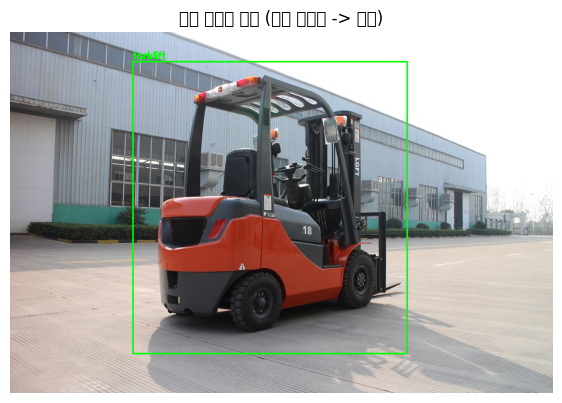

In [6]:
import glob
import cv2
import matplotlib.pyplot as plt

img_dir = f"{DATA_ROOT}/train/images"
lbl_dir = f"{DATA_ROOT}/train/labels"
sample_img_path = sorted(glob.glob(f"{img_dir}/*.jpg"))[0]
sample_lbl_path = sample_img_path.replace("images", "labels").replace(".jpg", ".txt")

print("--- 라벨 파일 원본 ---")
print(open(sample_lbl_path).read())

img = cv2.imread(sample_img_path)
h, w = img.shape[:2]
names = data_yaml["names"]

with open(sample_lbl_path) as f:
    for line in f:
        cls, xc, yc, bw, bh = map(float, line.split())
        cls = int(cls)
        x1, y1 = int((xc - bw / 2) * w), int((yc - bh / 2) * h)
        x2, y2 = int((xc + bw / 2) * w), int((yc + bh / 2) * h)
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(img, names[cls], (x1, max(y1 - 5, 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

plt.figure(figsize=(7, 7))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("라벨 시각화 예시 (원본 텍스트 -> 박스)")
plt.show()

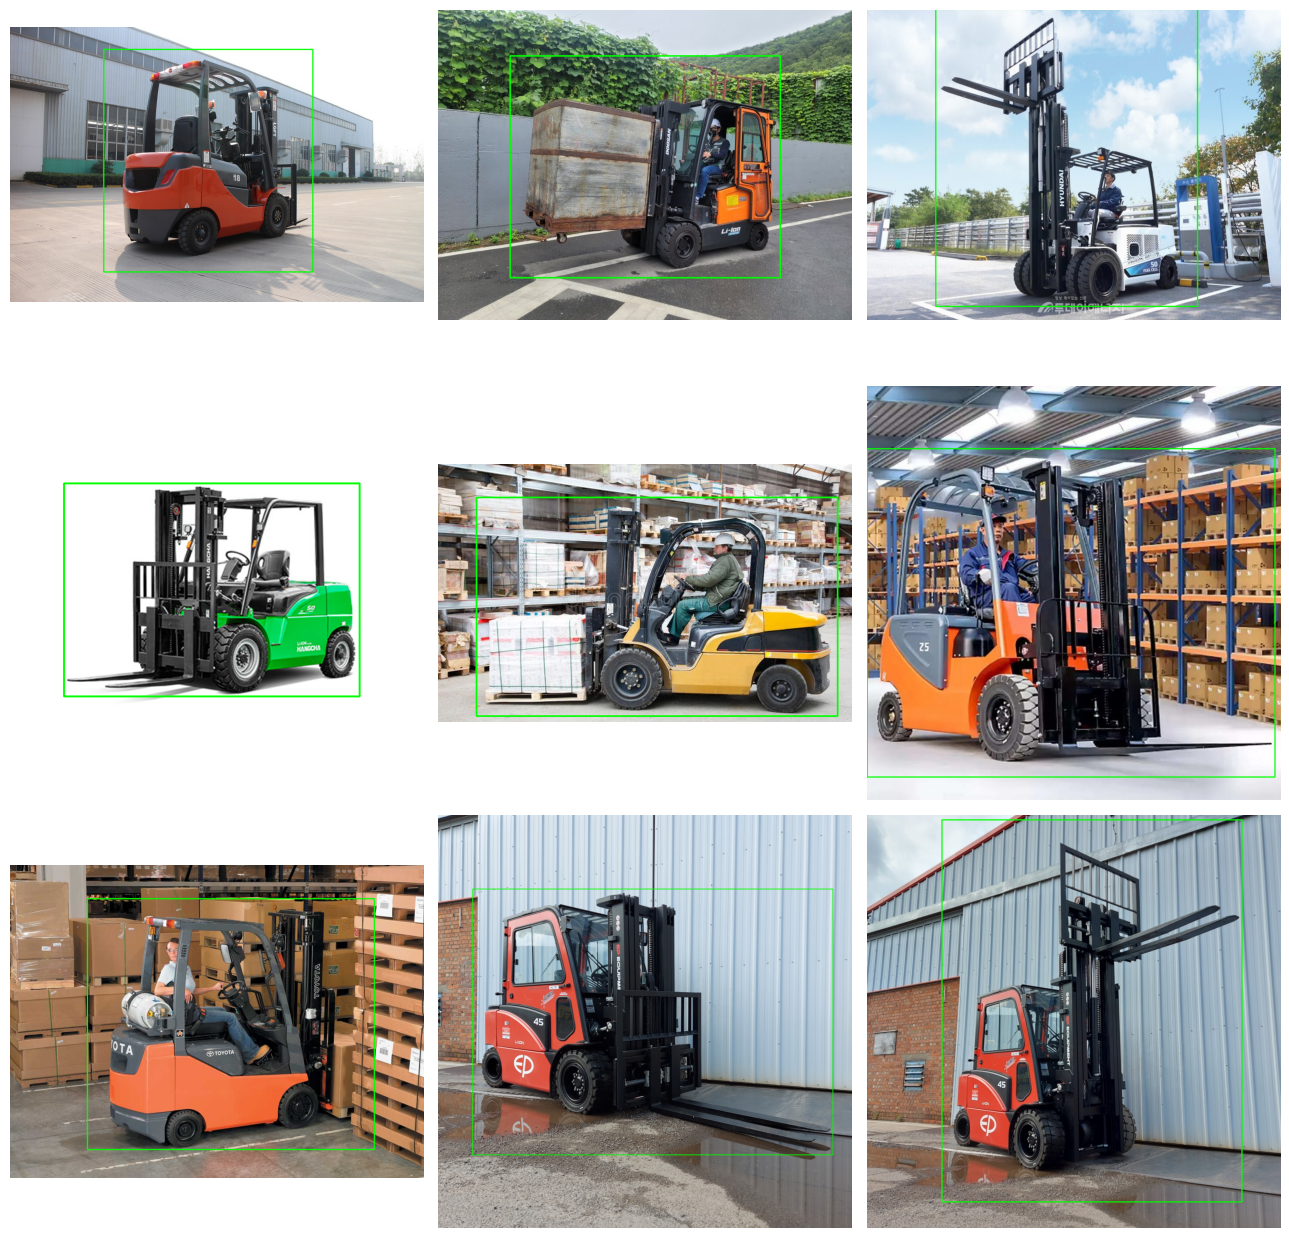

In [7]:
# 샘플 여러 장을 한 번에 확인 (데이터가 어떻게 생겼는지 감 잡기)
sample_paths = sorted(glob.glob(f"{img_dir}/*.jpg"))[:9]

fig, axes = plt.subplots(3, 3, figsize=(13, 13))
for ax, path in zip(axes.flat, sample_paths):
    im = cv2.imread(path)
    hh, ww = im.shape[:2]
    lp = path.replace("images", "labels").replace(".jpg", ".txt")
    with open(lp) as f:
        for line in f:
            cls, xc, yc, bw, bh = map(float, line.split())
            cls = int(cls)
            x1, y1 = int((xc - bw / 2) * ww), int((yc - bh / 2) * hh)
            x2, y2 = int((xc + bw / 2) * ww), int((yc + bh / 2) * hh)
            color = [(0, 255, 0), (0, 165, 255), (255, 0, 0)][cls % 3]
            cv2.rectangle(im, (x1, y1), (x2, y2), color, 2)
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. YOLOv8 모델 학습 (Train)

**YOLOv8n(nano)** 을 사용합니다 — 가장 가볍고 빠른 버전으로, Colab 무료 GPU(T4)로도 충분히 빠르게 학습됩니다.
COCO 데이터셋으로 이미 사전학습된 가중치에서 시작해서(Transfer Learning), 우리 안전모 데이터로 이어서 학습합니다.

이번 데이터셋은 train 이미지가 139장으로 작아서, T4 기준 **50 epoch도 몇 분이면 끝납니다** (이미지가 적을수록 1 epoch가 빨리 돕니다). 데이터가 적은 만큼 결과가 완벽하진 않을 수 있는데, 이는 실습에서 "데이터 양과 성능의 관계"를 직접 체감해볼 좋은 포인트입니다.

- `epochs`: 전체 데이터를 몇 번 반복 학습할지. 데이터가 적어 빨리 끝나므로 여유 있게 50으로 설정했습니다. 더 늘려서(100+) 성능 변화를 관찰해봐도 좋습니다.
- `imgsz`: 입력 이미지 크기. 640이 기본값입니다.
- `batch`: 한 번에 처리하는 이미지 수. 데이터가 적으므로 16이면 충분합니다.

In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")  # COCO 사전학습 가중치 자동 다운로드

train_results = model.train(
    data=f"{DATA_ROOT}/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    patience=15,
    project="helmet_detection",
    name="yolov8n_run1",
)

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_run1, nbs=64, nms=None, opset=None, optimize=False, optimizer=a

In [ ]:
# 학습 곡선(loss, mAP 추이) 확인
from IPython.display import Image, display

save_dir = model.trainer.save_dir
display(Image(filename=f"{save_dir}/results.png"))

## 5. 검증 (Validation)

In [ ]:
metrics = model.val()

print(f"mAP50     : {metrics.box.map50:.3f}")
print(f"mAP50-95  : {metrics.box.map:.3f}")
print(f"Precision : {metrics.box.mp:.3f}")
print(f"Recall    : {metrics.box.mr:.3f}")

In [ ]:
# 혼동 행렬(confusion matrix) - 어떤 클래스를 헷갈렸는지 확인
display(Image(filename=f"{save_dir}/confusion_matrix.png"))

## 6. 추론 (Inference / Test)

이제 학습이 끝난 모델로 **한 번도 보지 않은 test 이미지**에 실제로 안전모를 탐지시켜 봅니다.

In [ ]:
test_dir = f"{DATA_ROOT}/test/images"

pred_results = model.predict(source=test_dir, conf=0.3, save=True)
pred_save_dir = pred_results[0].save_dir
print("예측 결과 이미지 저장 위치:", pred_save_dir)

In [ ]:
pred_imgs = sorted(glob.glob(f"{pred_save_dir}/*.jpg"))[:6]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, path in zip(axes.flat, pred_imgs):
    im = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    ax.imshow(im)
    ax.axis("off")
plt.tight_layout()
plt.show()

### 우리 현장 사진으로 직접 테스트해보기

`cv_2d_recognition/workers.jpg` 같은 실제 현장 사진을 업로드해서, 학습된 모델이 실제로 안전모를 탐지하는지 확인해봅시다.
(이전에 만든 개념 일러스트의 "가짜 박스"와 비교해보세요!)

In [ ]:
from google.colab import files

uploaded = files.upload()  # 컴퓨터에서 workers.jpg 등 이미지 파일 선택

for fname in uploaded.keys():
    res = model.predict(source=fname, conf=0.3, save=True)
    out_path = f"{res[0].save_dir}/{fname}"
    im = cv2.cvtColor(cv2.imread(out_path), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(8, 8))
    plt.imshow(im)
    plt.axis("off")
    plt.title(fname)
    plt.show()

## 7. 모델 저장

In [ ]:
from google.colab import files

best_weights = f"{save_dir}/weights/best.pt"
print("학습된 최종 가중치:", best_weights)

files.download(best_weights)  # 로컬 컴퓨터로 다운로드

## 정리 & 다음 단계

- **데이터 준비**: Roboflow에서 라벨링된 공개 데이터셋을 받아왔습니다.
- **라벨 이해**: YOLO 형식(`class x_center y_center width height`, 0~1 정규화)을 확인했습니다.
- **학습**: YOLOv8n을 COCO 사전학습 가중치에서 전이학습(transfer learning) 시켰습니다.
- **검증**: mAP, Precision, Recall, Confusion Matrix로 성능을 확인했습니다.
- **추론**: 처음 보는 test 이미지 + 우리 현장 사진에 실제로 적용해봤습니다.

**더 해볼 것**
1. `epochs`를 늘리거나(50~100) 모델을 `yolov8s.pt` / `yolov8m.pt` 로 바꿔서 성능 비교하기
2. `conf`(confidence threshold)를 바꿔가며 Precision/Recall 트레이드오프 관찰하기
3. 안전조끼(vest) 등 다른 PPE 클래스가 포함된 데이터셋과 합쳐서 다중 클래스 모델 만들기
4. 학습된 모델을 영상(video)에 적용해서 실시간 탐지 데모 만들기 (`model.predict(source="video.mp4")`)